# Chapitre 10 - Cours 4 : Les retours utilisateurs

On peut raisonner longtemps sur la façon de construire une bonne application : la seule
manière de savoir si elle atteint son but est de la mettre entre les mains des
utilisateurs. Pour une application d'IA, leurs retours servent doublement : ils **évaluent**
le produit et ils constituent des **données** pour améliorer les modèles. L'interface
conversationnelle facilite le retour (on corrige l'assistant comme on corrigerait un
collègue), mais rend l'extraction des signaux plus difficile.

Sections du livre couvertes : *User Feedback*, *Extracting Conversational Feedback*
(*Natural language feedback*, *Other conversational feedback*), *Feedback Design*
(*When to collect feedback*, *How to collect feedback*), *Feedback Limitations*
(*Biases*, *Degenerate feedback loop*).

Plan :
1. les retours sont des données ;
2. retours explicites et implicites ;
3. extraire des signaux d'une conversation : heuristiques ;
4. extraire des signaux avec un petit LLM ;
5. la trajectoire du sentiment ;
6. concevoir la collecte des retours ;
7. les biais des retours ;
8. les boucles de rétroaction dégénérées.

In [1]:
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, confusion_matrix
from aie.plotting import set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, COLORS, annotate_bars
from aie.diagrams import Diagram
from aie import llm
from aie import ch10_architecture as A

set_style()
pd.set_option("display.max_colwidth", 80)
rng = np.random.default_rng(0)
embed = lambda texts: llm.embed(texts, llm.EMBED_MULTI)

## 1. Les retours sont des données (section *User Feedback*)

Les retours utilisateurs sont des **données propriétaires**, et les données sont un
avantage concurrentiel : un produit lancé tôt attire des utilisateurs, collecte leurs
retours, améliore ses modèles, attire plus d'utilisateurs... C'est le **volant d'inertie
des données** (« data flywheel ») du chapitre 8. Le livre note qu'une application open
source a du mal à en profiter : chacun la déploie chez soi et l'auteur ne voit rien.

Rappel essentiel : un retour utilisateur **est** une donnée utilisateur. Vie privée,
consentement et transparence sur l'usage s'appliquent.

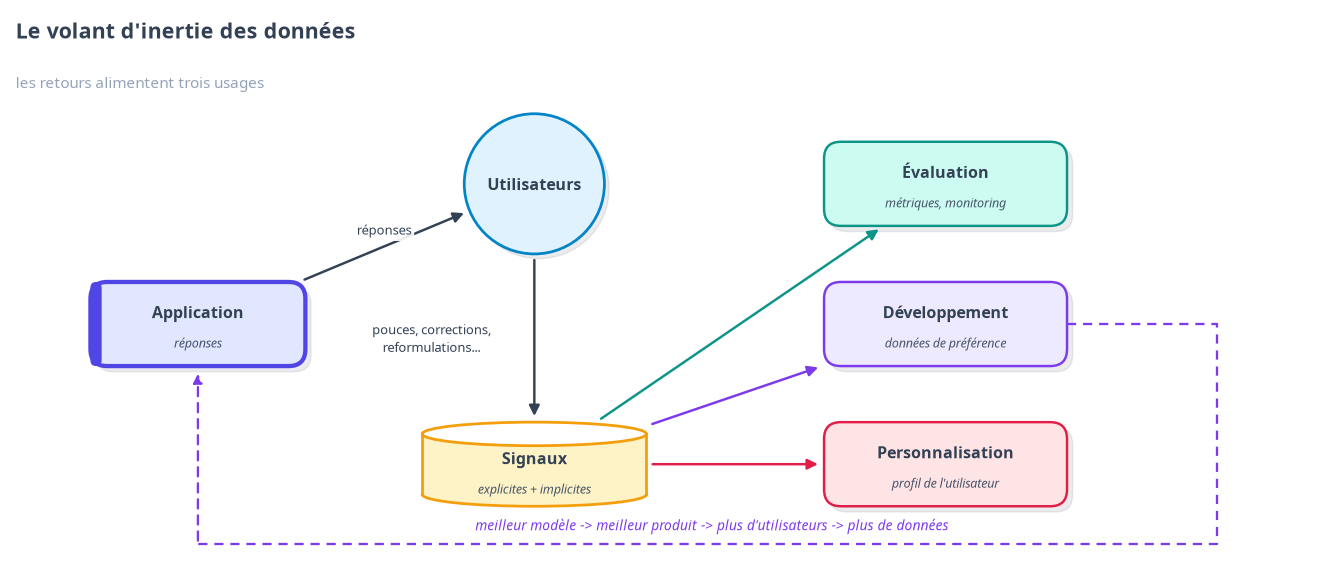

In [2]:
d = Diagram(14, 5.0, title="Le volant d'inertie des données", subtitle="les retours alimentent trois usages")
d.box("app", 2.0, 2.6, "Application", sub="réponses", color=INDIGO, kind="model", w=2.3)
d.box("users", 5.6, 4.1, "Utilisateurs", color=SKY, kind="user", w=1.5)
d.box("fb", 5.6, 1.1, "Signaux", sub="explicites + implicites", color=AMBER, kind="db", w=2.4)
d.box("eval", 10.0, 4.1, "Évaluation", sub="métriques, monitoring", color=TEAL, w=2.6)
d.box("dev", 10.0, 2.6, "Développement", sub="données de préférence", color=VIOLET, w=2.6)
d.box("perso", 10.0, 1.1, "Personnalisation", sub="profil de l'utilisateur", color=ROSE, w=2.6)
d.arrow("app", "users", "réponses")
d.arrow("users", "fb", "pouces, corrections,\nreformulations...", label_offset=(-1.1, 0))
d.arrow("fb", "eval", color=TEAL); d.arrow("fb", "dev", color=VIOLET); d.arrow("fb", "perso", color=ROSE)
d.line([(11.3, 2.6), (12.9, 2.6), (12.9, 0.25), (2.0, 0.25), (2.0, 2.1)], color=VIOLET, style="dashed", lw=1.5)
d.note(7.5, 0.45, "meilleur modèle -> meilleur produit -> plus d'utilisateurs -> plus de données", color=VIOLET, fontsize=9)
d.show()

> **À retenir.** Les retours servent à évaluer, développer et personnaliser ; ils sont la
> matière première du volant d'inertie des données, et restent des données personnelles.

## 2. Retours explicites et implicites (section *Extracting Conversational Feedback*)

- **Explicites** : l'utilisateur répond à une demande (pouce levé ou baissé, étoiles,
  « avons-nous résolu votre problème ? »). Faciles à interpréter, bien standardisés, mais
  **rares** (effort demandé) et **biaisés** (les mécontents répondent davantage).
- **Implicites** : déduits des actions (acheter le produit recommandé, copier le code,
  reformuler, abandonner). **Abondants**, mais **bruités** et propres à chaque application.

Exemple du livre : à trois suggestions d'hôtels à Sydney, répondre « réserve celui près des
galeries » révèle un goût pour l'art, tandis que « il n'y a rien sous 200 dollars ? » révèle
une sensibilité au prix et le fait que l'assistant n'a pas encore cerné l'utilisateur.

**Rare et propre, ou abondant et bruité ?** Simulons l'estimation du taux de satisfaction
réel (70 %) avec 2 000 conversations par jour. Retour explicite : 3 % des satisfaits et
10 % des insatisfaits répondent, sans erreur. Signal implicite : disponible pour tous, mais
ne dit vrai que dans 75 % des cas ; on le corrige en connaissant cette exactitude
(si $s$ est la part de signaux positifs et $a$ l'exactitude, $\hat p = (s - (1-a))/(2a-1)$).

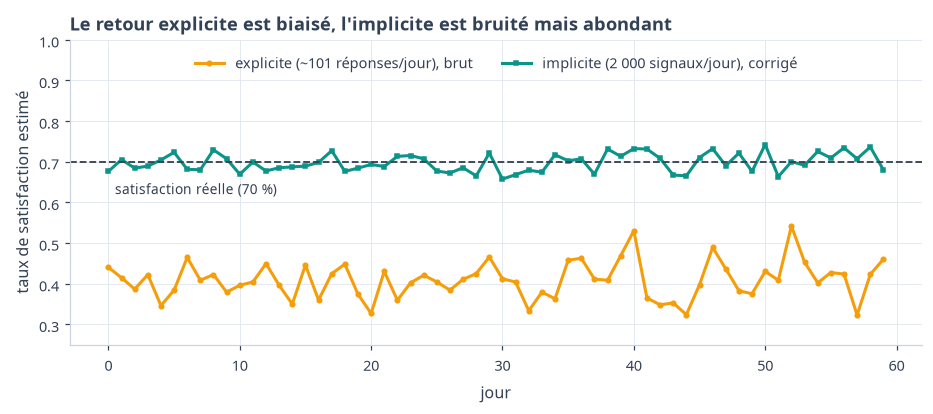

In [3]:
p_true, n_days = 0.70, 60
est_exp, est_imp, n_exp = [], [], []
for day in range(n_days):
    r = np.random.default_rng(day)
    happy = r.random(2000) < p_true
    gives = r.random(2000) < np.where(happy, 0.03, 0.10)
    est_exp.append(happy[gives].mean()); n_exp.append(gives.sum())
    a = 0.75
    sig = np.where(r.random(2000) < a, happy, ~happy)
    est_imp.append((sig.mean() - (1 - a)) / (2 * a - 1))
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(est_exp, "o-", color=AMBER, ms=3, label=f"explicite (~{np.mean(n_exp):.0f} réponses/jour), brut")
ax.plot(est_imp, "s-", color=TEAL, ms=3, label="implicite (2 000 signaux/jour), corrigé")
ax.axhline(p_true, color=SLATE, ls="--", lw=1.2); ax.text(0.5, p_true - 0.08, "satisfaction réelle (70 %)", color=SLATE, fontsize=9)
ax.set(xlabel="jour", ylabel="taux de satisfaction estimé", ylim=(0.25, 1.0),
       title="Le retour explicite est biaisé, l'implicite est bruité mais abondant")
ax.legend(loc="upper center", ncol=2); plt.show()

Le retour explicite est **systématiquement trop pessimiste** (biais de sélection : les
mécontents s'expriment plus) et fluctue avec peu de réponses ; le signal implicite, bien
que faux une fois sur quatre, donne une estimation non biaisée **si l'on connaît son
exactitude** (ce qui suppose une étude de calibration sur des conversations annotées). En
pratique on combine les deux.

> **À retenir.** Explicite : interprétable mais rare et biaisé. Implicite : abondant mais
> bruité et ambigu. Les deux se complètent.

## 3. Extraire des signaux d'une conversation : heuristiques (sections *Natural language feedback* et *Other conversational feedback*)

Le livre recense les signaux à suivre en production :
- **arrêt précoce** : l'utilisateur interrompt la génération, quitte l'application, dit
  « stop », ou laisse l'agent sans réponse ;
- **correction d'erreur** : message qui commence par « Non, ... » ou « Je voulais dire... »,
  **reformulation** de la demande, indications précises (« Bill est le suspect, pas la
  victime »), demandes de confirmation (« tu es sûr ? », « montre tes sources »), et
  **éditions** de la réponse (signal très fort, et paire de préférences gratuite) ;
- **plaintes** : réponse fausse, hors sujet, trop longue, pas assez détaillée... ;
- **sentiment** : frustration (« pff »), ou au contraire une colère qui se calme ;
- **refus du modèle** (« en tant qu'IA, je ne peux pas ») ;
- côté actions : **régénération**, organisation (supprimer, renommer, partager, mettre en
  favori), **longueur** de la conversation et **diversité** du dialogue (un bot qui se
  répète).

Notre fonction `A.extract_signals` implémente ces heuristiques (motifs sur le texte
normalisé, lexique de sentiment, similarité entre messages successifs pour les
reformulations, métadonnées d'interruption et de régénération). Voici une conversation du
jeu `A.CONVERSATIONS` (12 conversations annotées satisfait / insatisfait).

In [4]:
def show_conv(conv):
    for m in conv:
        tag = " [interrompue]" if m.get("interrupted") else (f" [action : {m['action']}]" if m.get("action") else "")
        print(f"{'U' if m['role'] == 'user' else 'A'}{tag} : {textwrap.shorten(m['content'], 110)}")

conv, lab = A.CONVERSATIONS[11]
show_conv(conv); print("\nétiquette :", "satisfait" if lab else "insatisfait")
pd.Series(A.extract_signals(conv)).round(2).to_frame("signal").T

U : Combien coûte la livraison ?
A [interrompue] : La livraison dépend de nombreux facteurs, notamment la destination, le poids, le mode de transport [...]
U : Stop. Combien coûte la livraison en France ?
A : Elle est gratuite dès 50 euros d'achat.
U : Trop long pour une réponse aussi simple

étiquette : insatisfait


,tours,reformulations,corrections,demandes_confirmation,plaintes,interruptions,regenerations,refus_modele,sentiment_moyen,sentiment_final,diversite_bot
signal,3.0,1.0,0.0,0.0,1.0,2.0,0.0,0.0,0.0,0.0,1.0


**Détecter une reformulation.** Deux messages successifs de l'utilisateur très similaires
indiquent souvent que la première réponse a manqué sa cible (figure 10-12 du livre). La
similarité lexicale (trigrammes) rate les reformulations qui changent les mots ; la
similarité d'embeddings les capte mieux mais confond aussi des relances légitimes sur le
même sujet. Comparons les deux sur des paires annotées.

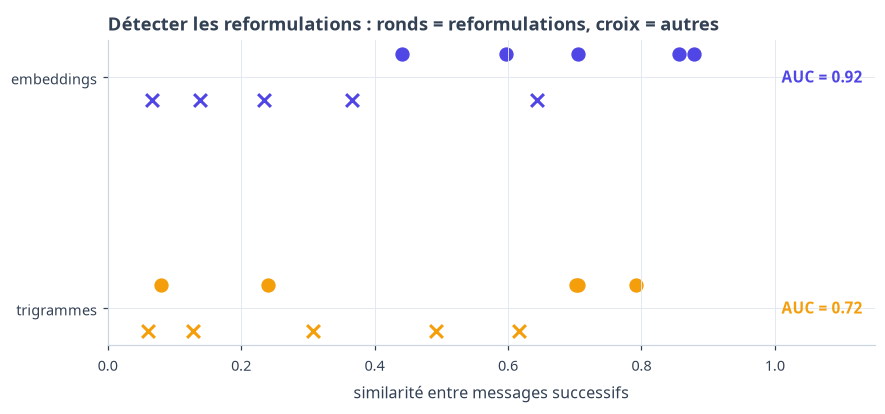

In [5]:
paires = [
    ("La batterie de mon téléphone se vide vite", "Pff, la batterie de mon téléphone se décharge très vite, que faire ?", 1),
    ("Je veux retourner un article", "Non, je veux juste savoir comment retourner un article", 1),
    ("Combien coûte la livraison ?", "Stop. Combien coûte la livraison en France ?", 1),
    ("J'ai oublié mon mot de passe", "Je n'arrive plus à me connecter, que faire pour récupérer l'accès ?", 1),
    ("Quel est le prix du casque ?", "Combien coûte ce casque audio ?", 1),
    ("Où est le magasin de Lyon ?", "Et le lundi c'est fermé ?", 0),
    ("Puis-je payer en plusieurs fois ?", "Tu es sûr ? Même pour une télé à 140 euros ?", 0),
    ("Quelle est la garantie d'une télévision ?", "Et pour un smartphone, quelle est la garantie ?", 0),
    ("Mon casque ne s'appaire pas", "Super, ça marche, merci beaucoup", 0),
    ("Livrez-vous en Belgique ?", "Et en Suisse, vous livrez ?", 0),
]
a_txt, b_txt, y_pair = zip(*paires)
Ea, Eb = embed(list(a_txt)), embed(list(b_txt))
sim_emb = (Ea * Eb).sum(1)
Ha, Hb = A.hash_embed(list(a_txt)), A.hash_embed(list(b_txt))
sim_hash = (Ha * Hb).sum(1)
fig, ax = plt.subplots(figsize=(9, 3.6))
y_pair = np.array(y_pair)
for k, (s, name, c) in enumerate([(sim_hash, "trigrammes", AMBER), (sim_emb, "embeddings MiniLM", INDIGO)]):
    ax.scatter(s[y_pair == 1], np.full((y_pair == 1).sum(), k + 0.1), color=c, s=70, marker="o", label=f"{name} : reformulation")
    ax.scatter(s[y_pair == 0], np.full((y_pair == 0).sum(), k - 0.1), color=c, s=70, marker="x", label=f"{name} : autre message")
    ax.text(1.01, k, f"AUC = {roc_auc_score(y_pair, s):.2f}", va="center", fontsize=10, color=c, fontweight="bold")
ax.set_yticks([0, 1], ["trigrammes", "embeddings"]); ax.set_xlim(0, 1.15); ax.set_xlabel("similarité entre messages successifs")
ax.set_title("Détecter les reformulations : ronds = reformulations, croix = autres")
plt.show()

Les embeddings séparent mieux les deux classes, mais pas parfaitement : « et pour un
smartphone, quelle est la garantie ? » ressemble beaucoup à la question précédente sans être
une reformulation. Une règle robuste combine plusieurs indices (similarité élevée **et**
marqueur de correction, ou interruption juste avant).

Calculons maintenant tous les signaux pour les 12 conversations, avec les embeddings pour
les reformulations, et combinons-les en un **score de satisfaction implicite**
(combinaison linéaire à poids choisis à la main, `A.SIGNAL_WEIGHTS`).

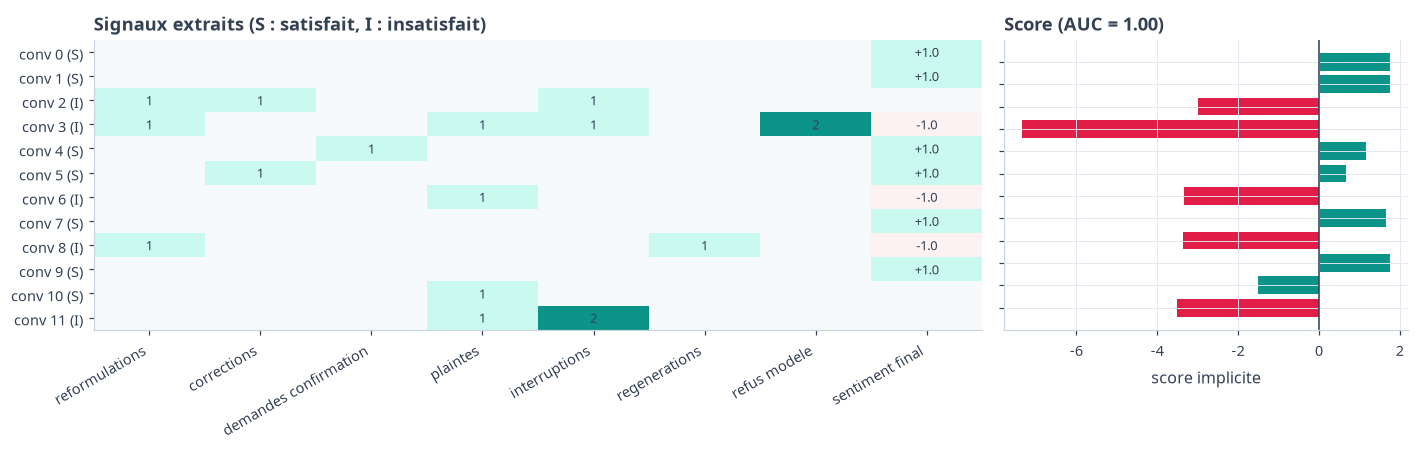

In [6]:
def sim_fn(a, b):
    E = embed([a, b]); return float(E[0] @ E[1])

rows = []
for i, (conv, lab) in enumerate(A.CONVERSATIONS):
    s = A.extract_signals(conv, sim_fn=sim_fn, rephrase_threshold=0.75)
    rows.append({"conv": i, "satisfait": lab, **s, "score": A.implicit_score(s)})
sig = pd.DataFrame(rows).set_index("conv")
show = ["reformulations", "corrections", "demandes_confirmation", "plaintes", "interruptions", "regenerations",
        "refus_modele", "sentiment_final"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
M = sig[show].values.astype(float)
ax[0].imshow(M, cmap="aie_div", vmin=-2, vmax=2, aspect="auto"); ax[0].grid(False)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if M[i, j]:
            ax[0].text(j, i, f"{M[i, j]:.0f}" if j < len(show) - 1 else f"{M[i, j]:+.1f}", ha="center", va="center", fontsize=8.5)
ax[0].set_xticks(range(len(show)), [s.replace("_", " ") for s in show], rotation=30, ha="right")
ax[0].set_yticks(range(len(sig)), [f"conv {i} ({'S' if l else 'I'})" for i, l in zip(sig.index, sig.satisfait)])
ax[0].set_title("Signaux extraits (S : satisfait, I : insatisfait)")
cols = [TEAL if l else ROSE for l in sig.satisfait]
ax[1].barh(range(len(sig)), sig.score, color=cols); ax[1].invert_yaxis(); ax[1].axvline(0, color=SLATE, lw=1)
ax[1].set_yticks(range(len(sig)), [""] * len(sig))
ax[1].set(xlabel="score implicite", title=f"Score (AUC = {roc_auc_score(sig.satisfait, sig.score):.2f})")
plt.tight_layout(); plt.show()

Les conversations insatisfaites (barres roses) cumulent reformulations, interruptions,
plaintes et sentiment final négatif. Sur ce petit jeu, le score **classe** correctement
toutes les conversations (AUC de 1), mais avec un seuil naturel à 0 il se tromperait sur
une conversation satisfaite qui contient une plainte en cours de route (« c'est pas clair,
quel pilote ? ») puis un neutre « ok je vais essayer » : son score est négatif. Le seuil,
comme les poids, doit être calibré. Le livre insiste : l'intuition donne un premier jeu de signaux, mais il faut des
**analyses de données et des études utilisateurs** pour valider leur interprétation. Avec
12 conversations, ce n'est qu'une illustration ; l'exercice 10.10 apprend les poids.

> **À retenir.** Interruptions, corrections, reformulations, plaintes, sentiment, refus et
> régénérations se détectent par heuristiques ou petits modèles ; aucun signal isolé n'est
> fiable, leur combinaison l'est davantage.

## 4. Extraire des signaux avec un petit LLM (section *Natural language feedback*)

Le livre note qu'on peut aussi utiliser l'IA pour **analyser** les retours. Demandons à
Qwen2.5-0.5B de classer des messages utilisateurs en quatre catégories : satisfait,
correction, plainte, neutre (`A.llm_feedback_label`), et comparons à une règle
heuristique, sur 16 messages annotés à la main.

In [7]:
gold = [
    ("La livraison prend 2 à 3 jours.", "Parfait, merci !", "satisfait"),
    ("Pour retourner un article, vérifiez d'abord les conditions...", "Non, je veux juste savoir comment retourner un article", "correction"),
    ("Je suis désolé, je ne peux pas vous aider.", "Inutile. Laisse tomber", "plainte"),
    ("La garantie est de 2 ans.", "En fait je parlais des téléviseurs, c'est pas 3 ans ?", "correction"),
    ("Annulez depuis votre espace client.", "Ça ne marche pas, le bouton est grisé !!", "plainte"),
    ("Annulez depuis votre espace client.", "Tu te répètes, c'est n'importe quoi", "plainte"),
    ("Au 12 rue de la République.", "Top, merci", "satisfait"),
    ("Vérifiez vos courriers indésirables.", "Toujours pas reçu, ras le bol", "plainte"),
    ("Oui, en 4 à 5 jours ouvrés.", "Génial", "satisfait"),
    ("Mettez à jour le pilote graphique.", "Ok je vais essayer", "neutre"),
    ("La livraison dépend de nombreux facteurs...", "Stop. Combien coûte la livraison en France ?", "correction"),
    ("Elle est gratuite dès 50 euros.", "Trop long pour une réponse aussi simple", "plainte"),
    ("Au 12 rue de la République.", "Et le lundi c'est fermé ?", "neutre"),
    ("Le seuil est de 150 euros.", "D'accord, merci", "satisfait"),
    ("Réinitialisez le casque.", "Super, ça marche, merci beaucoup", "satisfait"),
    ("Le magasin ouvre à 10 h.", "Je voulais dire le magasin de Lille, pas celui de Lyon", "correction"),
]

def heuristic_label(msg):
    if A._match_any(A.CORRECTION_PATTERNS + A.STOP_PATTERNS, msg):
        return "correction"
    s = A.sentiment_score(msg)
    if A._match_any(A.COMPLAINT_PATTERNS, msg) or s < 0:
        return "plainte"
    return "satisfait" if s > 0 else "neutre"

qwen_chat = lambda msgs: llm.chat(msgs, model_id=llm.SMALL, max_new_tokens=8)
fb = pd.DataFrame(gold, columns=["réponse précédente", "message", "vérité"])
fb["heuristique"] = [heuristic_label(m) for m in fb.message]
fb["Qwen 0,5B"] = [A.llm_feedback_label(m, a, qwen_chat) for a, m, _ in gold]
fb[["message", "vérité", "heuristique", "Qwen 0,5B"]]

,message,vérité,heuristique,"Qwen 0,5B"
0,"Parfait, merci !",satisfait,satisfait,satisfait
1,"Non, je veux juste savoir comment retourner un article",correction,correction,correction
2,Inutile. Laisse tomber,plainte,correction,plainte
3,"En fait je parlais des téléviseurs, c'est pas 3 ans ?",correction,correction,plainte
4,"Ça ne marche pas, le bouton est grisé !!",plainte,plainte,plainte
5,"Tu te répètes, c'est n'importe quoi",plainte,plainte,plainte
6,"Top, merci",satisfait,satisfait,plainte
7,"Toujours pas reçu, ras le bol",plainte,plainte,plainte
8,Génial,satisfait,satisfait,satisfait
9,Ok je vais essayer,neutre,neutre,correction


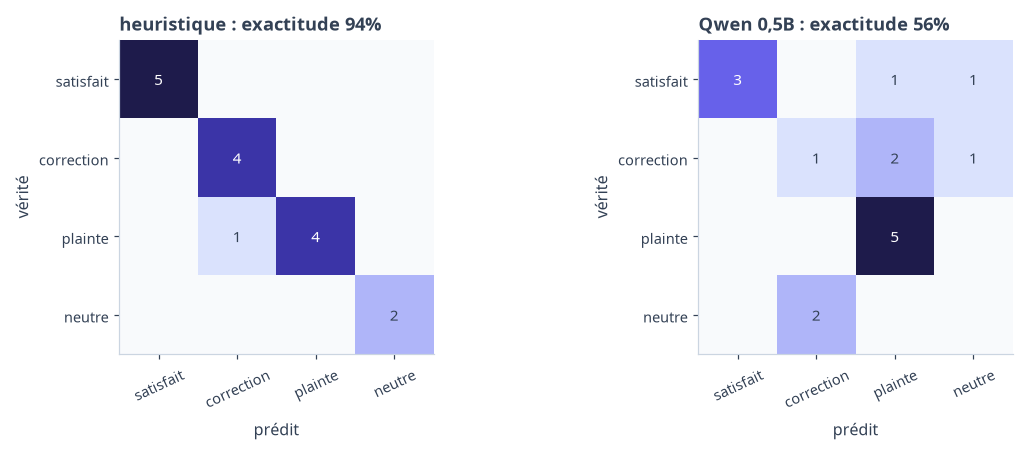

In [8]:
labs = A.FEEDBACK_LABELS
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, col in zip(axes, ["heuristique", "Qwen 0,5B"]):
    cm = confusion_matrix(fb["vérité"], fb[col], labels=labs)
    ax.imshow(cm, cmap="aie_seq"); ax.grid(False)
    for i in range(4):
        for j in range(4):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > 2 else SLATE)
    ax.set_xticks(range(4), labs, rotation=25); ax.set_yticks(range(4), labs)
    ax.set(xlabel="prédit", ylabel="vérité", title=f"{col} : exactitude {np.mean(fb[col] == fb['vérité']):.0%}")
plt.tight_layout(); plt.show()

Lisez honnêtement les deux matrices. Les heuristiques, écrites pour ce jeu de données, s'en
sortent bien ici mais ne généraliseront pas (chaque nouvelle formulation exige une nouvelle
règle). Le modèle de 0,5 milliard de paramètres, en zéro-shot, est nettement moins fiable :
il sur-utilise l'étiquette « plainte » (jusqu'à classer ainsi « Top, merci ») et confond
corrections et questions neutres. Un modèle plus grand,
quelques exemples dans le prompt (few-shot), ou un petit classifieur entraîné sur des
messages annotés feraient mieux ; le principe reste : **valider l'extracteur de signaux sur
des données annotées avant de s'en servir comme métrique**.

> **À retenir.** Un LLM peut extraire des signaux de retours en langage naturel, mais un
> très petit modèle est peu fiable ; tout extracteur de signaux doit être évalué comme un
> classifieur.

## 5. La trajectoire du sentiment (section *Natural language feedback*)

Le livre évoque les centres d'appels qui suivent la voix des clients : si elle monte,
quelque chose ne va pas ; une conversation commencée en colère et terminée apaisée a
probablement résolu le problème. Traçons le sentiment lexical message par message.

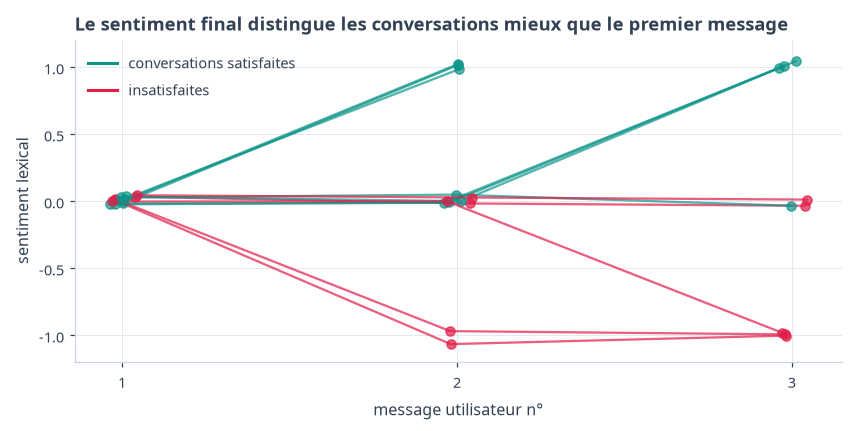

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, (conv, lab) in enumerate(A.CONVERSATIONS):
    s = [A.sentiment_score(m["content"]) for m in conv if m["role"] == "user"]
    ax.plot(np.arange(1, len(s) + 1) + rng.normal(0, 0.03), np.array(s) + rng.normal(0, 0.03, len(s)), "o-",
            color=TEAL if lab else ROSE, alpha=0.7, lw=1.5)
ax.plot([], [], color=TEAL, label="conversations satisfaites"); ax.plot([], [], color=ROSE, label="insatisfaites")
ax.set(xlabel="message utilisateur n°", ylabel="sentiment lexical", xticks=[1, 2, 3], ylim=(-1.2, 1.2),
       title="Le sentiment final distingue les conversations mieux que le premier message")
ax.legend(); plt.show()

Le premier message est presque toujours neutre (on pose une question) ; c'est l'**évolution**
qui est informative. Le livre souligne aussi le caractère un peu dystopique de cette
surveillance : elle doit rester proportionnée et transparente.

> **À retenir.** Le sentiment se lit comme une trajectoire : sa valeur finale et sa
> variation renseignent plus que sa valeur initiale.

## 6. Concevoir la collecte des retours (section *Feedback Design*)

**Quand ?** Tout au long du parcours, de façon **non intrusive** :
- **au début**, pour calibrer (niveau d'un apprenant, voix pour le mot d'éveil) ; à rendre
  optionnel quand ce n'est pas indispensable, avec un réglage neutre par défaut ;
- **quand quelque chose se passe mal** (hallucination, refus injustifié, lenteur) :
  pouce baissé, régénération, changement de modèle, et surtout permettre à l'utilisateur
  d'**accomplir quand même sa tâche** (éditer, collaborer avec l'IA, passer à un humain).
  L'« inpainting » des générateurs d'images est un modèle : l'utilisateur corrige une zone,
  et le développeur obtient un retour de grande qualité ;
- **quand le modèle doute** : montrer deux options (deux résumés), comme les comparaisons
  côte à côte de ChatGPT ou les débuts de réponses de Gemini, ou demander « est-ce la même
  personne ? » comme Google Photos ;
- **quand tout va bien** : débat ouvert. Les recommandations d'Apple déconseillent de
  demander à la fois retours positifs et négatifs, mais des équipes produit veulent savoir
  ce que les utilisateurs adorent. Compromis : ne solliciter qu'une petite fraction des
  utilisateurs.

**Combien d'utilisateurs solliciter ?** Pour estimer une proportion à $\pm\varepsilon$
près (95 %), il faut $n \approx 1{,}96^2\,p(1-p)/\varepsilon^2$ réponses ; avec un taux de
réponse $r$ et une fraction sollicitée $f$, il faut $N = n/(r f)$ utilisateurs actifs.

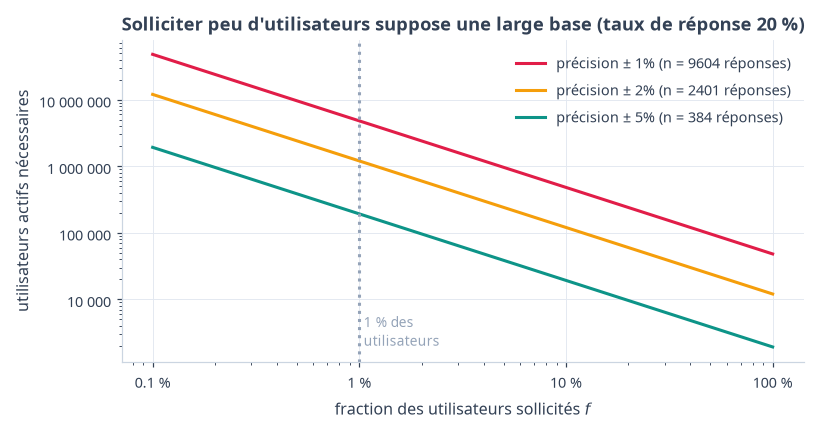

In [10]:
eps = np.array([0.01, 0.02, 0.05])
f = np.logspace(-3, 0, 50)
r_rep = 0.2
fig, ax = plt.subplots(figsize=(8, 3.8))
for e, c in zip(eps, [ROSE, AMBER, TEAL]):
    n = 1.96 ** 2 * 0.25 / e ** 2
    ax.plot(f, n / (r_rep * f), color=c, label=f"précision ± {e:.0%} (n = {n:.0f} réponses)")
ax.axvline(0.01, color=GRAY, ls=":"); ax.text(0.0105, 2e3, "1 % des\nutilisateurs", fontsize=9, color=GRAY)
ax.set(xscale="log", yscale="log", xlabel="fraction des utilisateurs sollicités $f$",
       ylabel="utilisateurs actifs nécessaires", title="Solliciter peu d'utilisateurs suppose une large base (taux de réponse 20 %)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:g} %"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ")))
ax.xaxis.set_minor_formatter(plt.NullFormatter()); ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.legend(); plt.show()

Avec 1 % des utilisateurs sollicités et 20 % de réponses, une précision de ±2 points exige
environ un million d'utilisateurs actifs sur la période : c'est réservé aux grands produits.
Et plus la fraction sollicitée est faible, plus le risque de biais est grand (qui accepte de
répondre ?).

**Comment ?** Le retour doit s'intégrer au flux de travail, sans effort supplémentaire,
être facile à ignorer, et les utilisateurs doivent avoir intérêt à bien répondre. Exemples
cités : Midjourney (agrandir une image = signal positif fort, variations = signal positif
plus faible, tout régénérer = aucune image ne convient) et GitHub Copilot (Tab pour
accepter, continuer à taper pour ignorer). Les applications autonomes comme ChatGPT sont
désavantagées : elles ne savent pas si l'email rédigé a été envoyé, contrairement à Gmail.

| Action de l'utilisateur | Signal | Force |
|---|---|---|
| agrandir une des 4 images (Midjourney) | cette image est la meilleure | forte, positive |
| demander des variations d'une image | image prometteuse | moyenne, positive |
| régénérer les 4 images | aucune ne convient (ou curiosité) | ambiguë, plutôt négative |
| accepter une suggestion avec Tab (Copilot) | suggestion utile | forte, positive |
| continuer à taper | suggestion ignorée | faible, négative |
| éditer la réponse | réponse imparfaite + version corrigée | très forte (préférence) |

**Les éditions comme données de préférence.** Une édition fournit un triplet
(requête, réponse gagnante = version éditée, réponse perdante = original), directement
utilisable pour l'alignement par préférences (chapitre 2, DPO / RLHF).

In [11]:
edits = [
    {"requete": "Résume la politique de retour", "original": "Vous pouvez retourner les articles dans un certain délai.",
     "edite": "Vous avez 30 jours après réception pour retourner un article non utilisé."},
    {"requete": "Délai de livraison en Belgique ?", "original": "La livraison prend 2 à 3 jours.",
     "edite": "La livraison en Belgique prend 4 à 5 jours ouvrés (7,90 euros)."},
]
prefs = pd.DataFrame([{"prompt": e["requete"], "chosen": e["edite"], "rejected": e["original"]} for e in edits])
prefs

,prompt,chosen,rejected
0,Résume la politique de retour,Vous avez 30 jours après réception pour retourner un article non utilisé.,Vous pouvez retourner les articles dans un certain délai.
1,Délai de livraison en Belgique ?,"La livraison en Belgique prend 4 à 5 jours ouvrés (7,90 euros).",La livraison prend 2 à 3 jours.


**Contexte, consentement, visibilité.** Pour analyser un pouce baissé, il faut les 5 à 10
derniers tours de dialogue, qui peuvent contenir des données personnelles : d'où les clauses
de conditions d'utilisation ou un flux de « don de données » (case à cocher pour partager
la conversation avec le retour). Expliquer l'usage des retours motive à en donner. Ne pas
demander l'impossible (choisir entre deux réponses à une question de statistiques qu'on ne
comprend pas, sans option « je ne sais pas »), éviter les interfaces ambiguës (l'anecdote
des émojis inversés de Luma, qui transformait des avis positifs en notes de 1/5), et
choisir entre retours **privés** (plus sincères) et **publics** (plus explicables) : X a
vu le nombre de « j'aime » augmenter après les avoir rendus privés.

Le schéma suivant résume l'instrumentation des retours dans notre application.

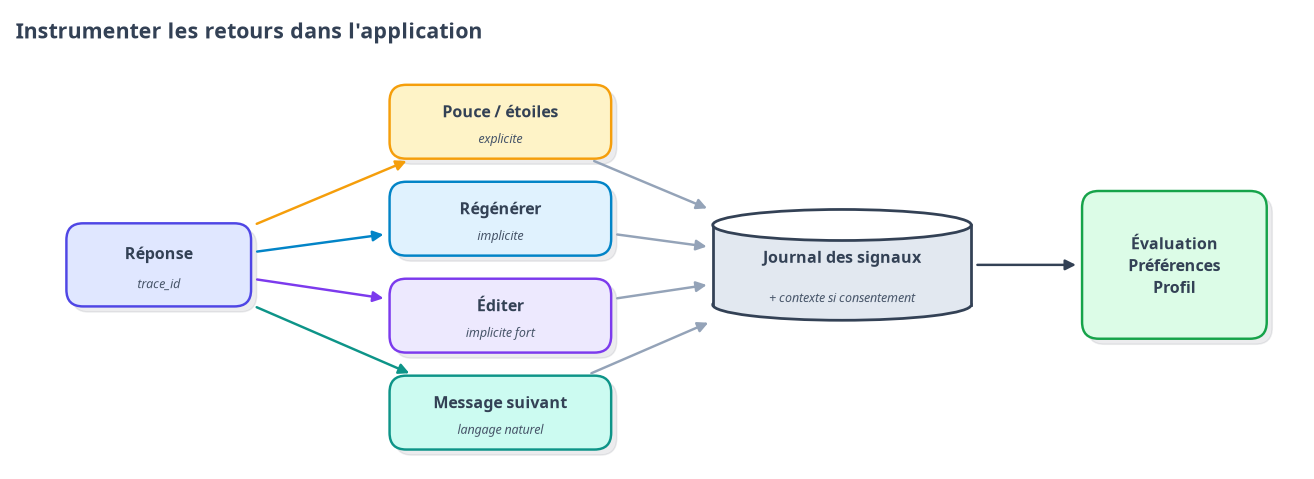

In [12]:
d = Diagram(14, 4.4, title="Instrumenter les retours dans l'application")
d.box("rep", 1.6, 2.2, "Réponse", sub="trace_id", color=INDIGO, w=2.0)
acts = [("up", "Pouce / étoiles", "explicite", AMBER), ("regen", "Régénérer", "implicite", SKY),
        ("edit", "Éditer", "implicite fort", VIOLET), ("conv", "Message suivant", "langage naturel", TEAL)]
for i, (n, t, s, c) in enumerate(acts):
    d.box(n, 5.3, 3.75 - 1.05 * i, t, sub=s, color=c, w=2.4, h=0.8)
    d.arrow("rep", n, color=c)
d.box("log", 9.0, 2.2, "Journal des signaux", sub="+ contexte si consentement", color=SLATE, kind="db", w=2.8, h=1.2)
for n, *_ in acts:
    d.arrow(n, "log", color=GRAY)
d.box("use", 12.6, 2.2, "Évaluation\nPréférences\nProfil", color=GREEN, w=2.0, h=1.6)
d.arrow("log", "use")
d.show()

> **À retenir.** Collecter au bon moment (début, échec, doute), sans friction, dans le flux
> de travail ; relier chaque retour à sa trace ; respecter consentement et vie privée ; les
> éditions fournissent des paires de préférences.

## 7. Les biais des retours (section *Biases*)

Comme toute donnée, les retours sont biaisés ; il faut connaître ces biais pour les
interpréter. Le livre en cite quatre familles.

**Biais de complaisance** (« leniency bias ») : noter plus généreusement que mérité, pour
éviter le conflit ou parce que noter mal déclenche des questions. Chez Uber en 2015, la note
moyenne d'un chauffeur était de 4,8 et passer sous 4,6 exposait à une désactivation. Le
biais n'est pas rédhibitoire (la note distingue encore bons et mauvais chauffeurs), mais il
faut regarder la **distribution**. Simulons deux chauffeurs, l'un bon, l'autre médiocre.

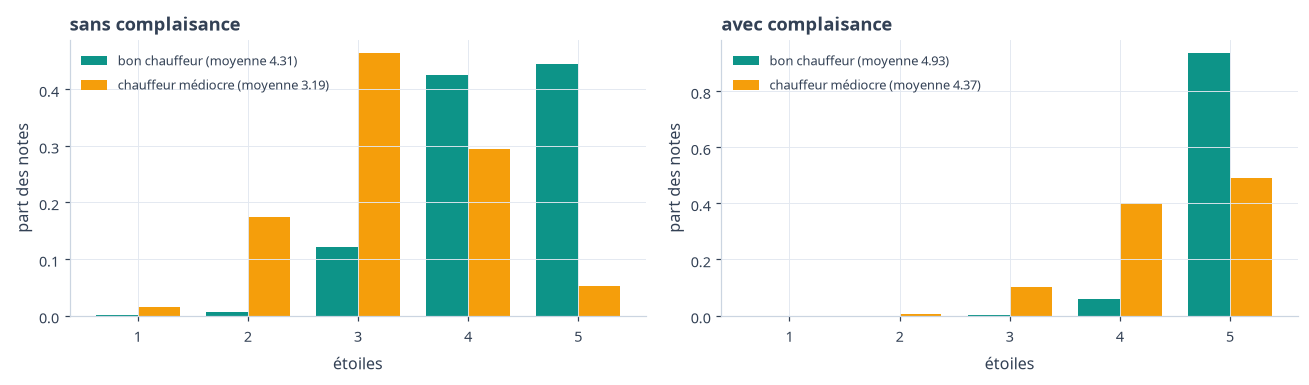

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for k, (q, name, c) in enumerate([(0.85, "bon chauffeur", TEAL), (0.55, "chauffeur médiocre", AMBER)]):
    for j, (len_, title) in enumerate([(0.0, "sans complaisance"), (1.3, "avec complaisance")]):
        rt = A.leniency_ratings(q, n=5000, leniency=len_, seed=k)
        counts = np.bincount(rt, minlength=6)[1:] / len(rt)
        ax[j].bar(np.arange(1, 6) + (k - 0.5) * 0.38, counts, 0.38, color=c, label=f"{name} (moyenne {rt.mean():.2f})")
        ax[j].set(xlabel="étoiles", ylabel="part des notes", title=title, xticks=range(1, 6))
        ax[j].legend(fontsize=8.5, loc="upper left")
plt.tight_layout(); plt.show()

Avec complaisance, presque tout le monde a 5 étoiles et l'écart entre les deux chauffeurs se
réduit à quelques dixièmes, concentrés dans la part de 4 étoiles (qui devient le signal
d'un problème). Le livre suggère de remplacer les chiffres par des libellés moins chargés
(« Super course », « Plutôt bien », « Rien à signaler »...), pour libérer la nuance.

**Hasard** : faute de motivation, l'utilisateur clique au hasard (deux longues réponses côte
à côte qu'il ne lit pas).

**Biais de position** : la première option est plus souvent choisie, qu'elle soit
meilleure ou non. Remèdes cités : **varier aléatoirement** les positions, ou **modéliser**
l'effet de la position. Simulons des comparaisons A/B où A est réellement préférée dans
40 % des cas, avec une fraction $\pi$ d'utilisateurs qui cliquent toujours sur la première
option. Avec randomisation, on peut même estimer $\pi$ et corriger :
$P(A \mid A\ \text{en premier}) - P(A \mid A\ \text{en second}) = \pi$, et
$q = P(A \mid A\ \text{en second})/(1-\pi)$.

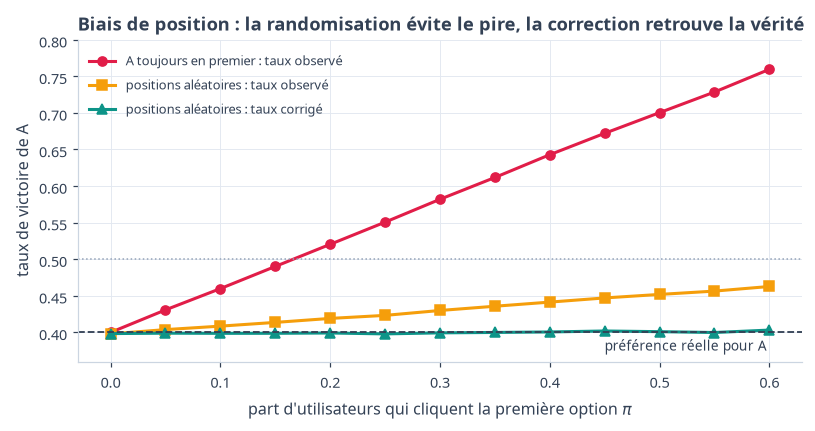

In [14]:
pis = np.linspace(0, 0.6, 13)
naive = [A.simulate_position_bias(20000, 0.4, p, randomize=False, seed=1)["observe"] for p in pis]
rand = [A.simulate_position_bias(20000, 0.4, p, randomize=True, seed=1) for p in pis]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(pis, naive, "o-", color=ROSE, label="A toujours en premier : taux observé")
ax.plot(pis, [r["observe"] for r in rand], "s-", color=AMBER, label="positions aléatoires : taux observé")
ax.plot(pis, [r["corrige"] for r in rand], "^-", color=TEAL, label="positions aléatoires : taux corrigé")
ax.axhline(0.4, color=SLATE, ls="--", lw=1.2); ax.text(0.45, 0.375, "préférence réelle pour A", fontsize=9, color=SLATE)
ax.axhline(0.5, color=GRAY, ls=":", lw=1)
ax.set(xlabel="part d'utilisateurs qui cliquent la première option $\\pi$", ylabel="taux de victoire de A",
       title="Biais de position : la randomisation évite le pire, la correction retrouve la vérité", ylim=(0.36, 0.8))
ax.legend(fontsize=8.5); plt.show()

Sans randomisation, le biais de position peut faire **gagner A alors qu'elle est moins
bonne** (au-delà de $\pi \approx 0{,}17$, la courbe rose dépasse 50 %). La randomisation
ramène l'estimation vers 50 % (le biais dilue le signal sans l'inverser), et la correction
retrouve 40 %.

**Biais de préférence** : préférer la réponse la plus **longue** même moins exacte (la
longueur se voit plus que l'inexactitude), ou la **dernière** lue (biais de récence). On
retrouve le biais de verbosité des juges IA (chapitre 3).

**Biais de sélection** : seuls certains utilisateurs répondent (section 2). Visualisons
l'écart entre satisfaction réelle et observée selon le rapport des taux de réponse.

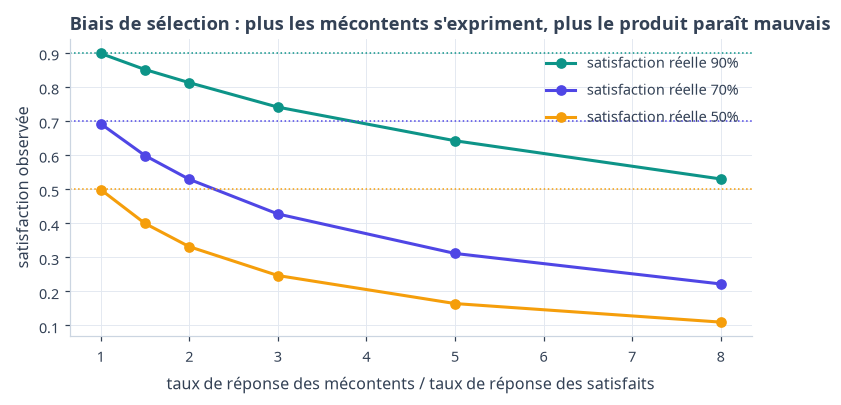

In [15]:
ratios = np.array([1, 1.5, 2, 3, 5, 8])
fig, ax = plt.subplots(figsize=(8, 3.5))
for t, c in [(0.9, TEAL), (0.7, INDIGO), (0.5, AMBER)]:
    obs = [A.simulate_selection_bias(t, 0.02, 0.02 * rr, n=200_000, seed=0)["observee"] for rr in ratios]
    ax.plot(ratios, obs, "o-", color=c, label=f"satisfaction réelle {t:.0%}")
    ax.axhline(t, color=c, ls=":", lw=1)
ax.set(xlabel="taux de réponse des mécontents / taux de réponse des satisfaits", ylabel="satisfaction observée",
       title="Biais de sélection : plus les mécontents s'expriment, plus le produit paraît mauvais")
ax.legend(); plt.show()

> **À retenir.** Complaisance, hasard, position, préférence (longueur, récence) et
> sélection déforment les retours ; regardez les distributions, randomisez les positions
> et corrigez quand on sait modéliser le biais.

## 8. Les boucles de rétroaction dégénérées (section *Degenerate feedback loop*)

On n'obtient de retours **que sur ce qu'on montre**. Quand ces retours modifient le
système, ses prédictions influencent les retours suivants, qui influencent la version
suivante : une **boucle de rétroaction dégénérée** peut amplifier un écart initial minime.
Exemple du livre : deux vidéos presque équivalentes ; A est classée un peu plus haut, reçoit
plus de clics (parce qu'elle est en haut), le système la remonte encore... On parle de
biais d'exposition, de popularité, de bulles de filtre.

Simulons un système de recommandation de 5 éléments dont les qualités réelles (probabilité
de clic en tête de liste) sont proches : 0,30 ; **0,33** (le meilleur) ; 0,27 ; 0,31 ; 0,25.
La probabilité de clic est la qualité multipliée par un facteur de position $1/\text{rang}$.
À chaque tour, le système classe les éléments selon leur taux de clic estimé. Trois
politiques :
- **gloutonne** : on classe selon le taux de clic brut (boucle dégénérée) ;
- **$\varepsilon$-gloutonne** : 20 % des affichages dans un ordre aléatoire (exploration) ;
- **IPW** (« inverse propensity weighting ») : chaque clic est divisé par le facteur de
  position avant d'estimer la qualité, ce qui corrige le biais d'exposition.

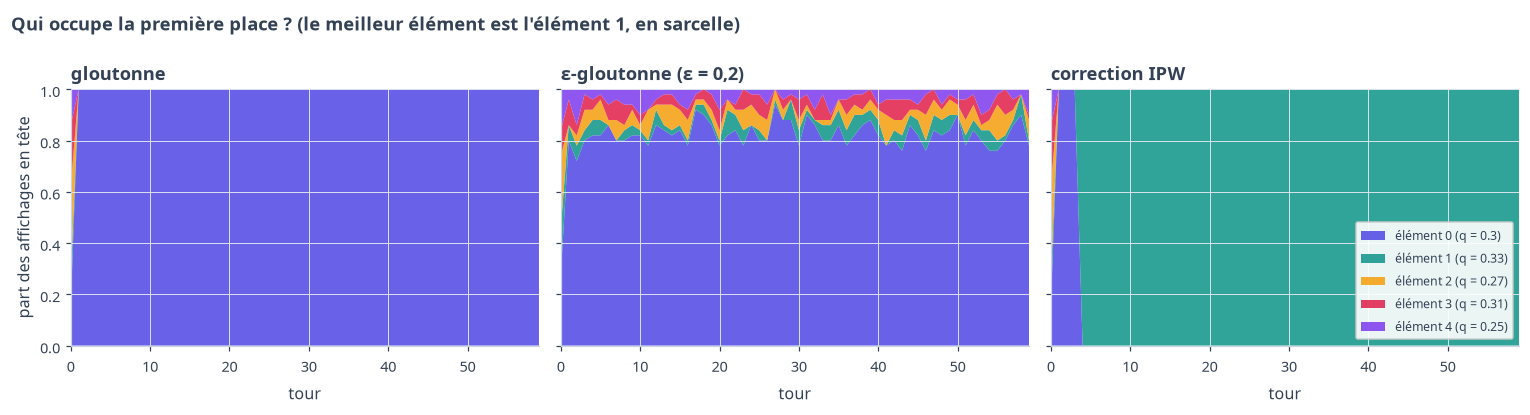

In [16]:
quals = [0.30, 0.33, 0.27, 0.31, 0.25]
pols = [("greedy", "gloutonne"), ("epsilon", "ε-gloutonne (ε = 0,2)"), ("ipw", "correction IPW")]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (pol, name) in zip(axes, pols):
    r = A.simulate_feedback_loop(quals, n_rounds=60, policy=pol, eps=0.2 if pol == "epsilon" else 0.0, seed=0)
    ax.stackplot(np.arange(60), r["top_share"].T, colors=[INDIGO, TEAL, AMBER, ROSE, VIOLET], alpha=0.85,
                 labels=[f"élément {i} (q = {q})" for i, q in enumerate(quals)])
    ax.set(xlabel="tour", title=name, xlim=(0, 59), ylim=(0, 1))
axes[0].set_ylabel("part des affichages en tête")
axes[2].legend(fontsize=8, loc="lower right", framealpha=0.9, frameon=True)
plt.suptitle("Qui occupe la première place ? (le meilleur élément est l'élément 1, en sarcelle)", x=0.01, ha="left",
             fontweight="bold")
plt.tight_layout(); plt.show()

La politique gloutonne se fige sur l'élément qui a eu de la chance au départ (ici pas le
meilleur) : une fois en tête, il reçoit plus de clics à cause de sa position, et son
avance s'auto-entretient. L'exploration ne suffit pas toujours : tant que les estimations
mélangent qualité et position, l'élément en tête reste avantagé. La correction IPW, qui
compare les éléments « à position égale », retrouve le meilleur. Répétons sur plusieurs
graines pour mesurer la fréquence à laquelle chaque politique converge vers le meilleur
élément.

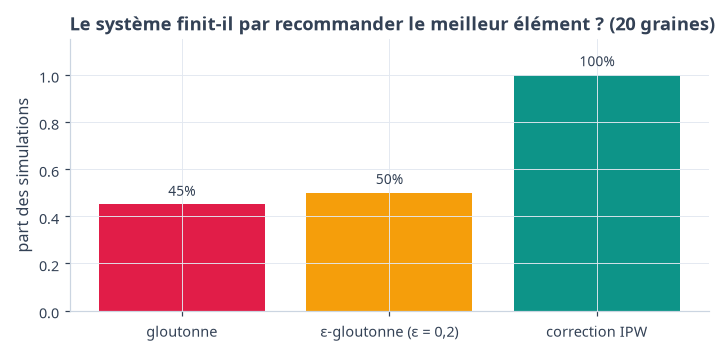

In [17]:
succ = {}
for pol, name in pols:
    finals = [A.simulate_feedback_loop(quals, n_rounds=60, policy=pol, eps=0.2 if pol == "epsilon" else 0.0, seed=s)["top_share"][-10:].mean(0).argmax()
              for s in range(20)]
    succ[name] = np.mean(np.array(finals) == 1)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.bar(list(succ), list(succ.values()), color=[ROSE, AMBER, TEAL]); annotate_bars(ax, "{:.0%}")
ax.set(ylabel="part des simulations", ylim=(0, 1.15), title="Le système finit-il par recommander le meilleur élément ? (20 graines)")
plt.show()

**Au-delà des recommandations.** Le même mécanisme peut transformer un produit : quelques
utilisateurs aiment les photos de chats, le système en génère plus, attire les amateurs de
chats... et devient un « paradis des chats » ; il peut amplifier des biais bien plus graves.
Pour les modèles conversationnels, entraîner sur les retours peut apprendre au modèle à
dire ce que l'utilisateur veut entendre plutôt que ce qui est exact : la **complaisance**
(« sycophancy », Sharma et al., 2023). Illustration minimale : un modèle choisit, pour
chaque question, entre **contredire** l'utilisateur quand il se trompe (exact) ou
**l'approuver** ; les utilisateurs récompensent l'approbation un peu plus que l'exactitude.

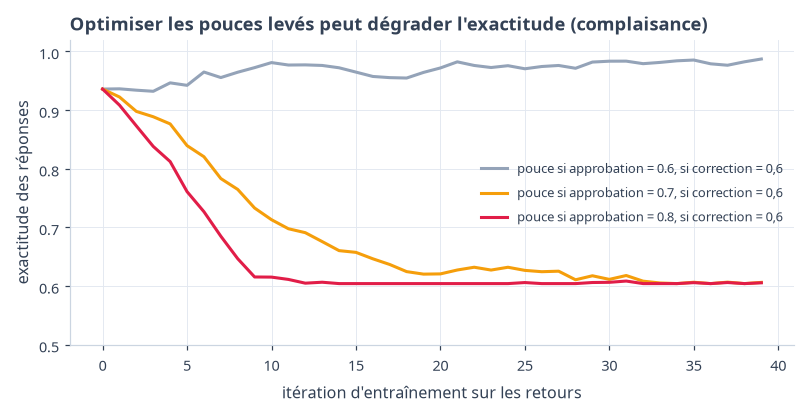

In [18]:
def sycophancy_loop(reward_agree=0.8, reward_correct=0.6, lr=0.5, rounds=40, p_user_wrong=0.4, seed=0):
    r = np.random.default_rng(seed)
    p_agree = 0.1                   # probabilité initiale d'approuver un utilisateur qui se trompe
    hist = []
    for _ in range(rounds):
        n = 500
        wrong = r.random(n) < p_user_wrong
        agree = r.random(n) < p_agree
        # retour : pouce levé avec proba reward_agree si le modèle approuve, reward_correct s'il corrige
        thumbs = np.where(agree, r.random(n) < reward_agree, r.random(n) < reward_correct)
        a_mask, c_mask = wrong & agree, wrong & ~agree
        gain = thumbs[a_mask].mean() - thumbs[c_mask].mean() if a_mask.any() and c_mask.any() else 0.0
        p_agree = float(np.clip(p_agree + lr * gain * p_agree * (1 - p_agree) * 4, 0.01, 0.99))
        accuracy = 1 - p_user_wrong * p_agree
        hist.append((p_agree, accuracy))
    return np.array(hist)

fig, ax = plt.subplots(figsize=(8.5, 3.6))
for ra, c in [(0.6, GRAY), (0.7, AMBER), (0.8, ROSE)]:
    h = sycophancy_loop(reward_agree=ra)
    ax.plot(h[:, 1], color=c, label=f"pouce si approbation = {ra}, si correction = 0,6")
ax.set(xlabel="itération d'entraînement sur les retours", ylabel="exactitude des réponses",
       title="Optimiser les pouces levés peut dégrader l'exactitude (complaisance)", ylim=(0.5, 1.02))
ax.legend(fontsize=8.5); plt.show()

Dès que l'approbation est un peu mieux récompensée que la correction, la boucle pousse le
modèle vers la complaisance et l'exactitude chute ; à récompense égale (courbe grise),
l'exactitude reste élevée (elle ne fluctue qu'au gré du bruit des retours). Le livre conclut : les retours sont cruciaux, mais utilisés sans discernement ils
peuvent perpétuer des biais et **détruire** le produit. Avant de les intégrer, comprenez
leurs limites et leur impact.

> **À retenir.** On n'a de retours que sur ce qu'on montre : sans exploration ni
> correction du biais d'exposition, la boucle se fige sur un choix arbitraire ; optimiser
> naïvement l'approbation produit de la complaisance.

## Synthèse

- Les retours utilisateurs sont des **données** (propriétaires, personnelles) qui servent
  l'évaluation, le développement et la personnalisation.
- **Explicites** (rares, biaisés, clairs) et **implicites** (abondants, bruités) se
  complètent ; l'interface conversationnelle multiplie les signaux implicites :
  interruptions, corrections, reformulations, plaintes, sentiment, refus, régénérations,
  éditions, longueur et diversité des dialogues.
- Les extraire demande heuristiques, embeddings ou modèles, **validés comme des
  classifieurs** ; un modèle de 0,5 B est un extracteur peu fiable.
- **Concevoir** la collecte : au bon moment, sans friction, dans le flux de travail, avec
  consentement ; les éditions donnent des paires de préférences (chapitre 2, alignement ;
  chapitre 8, volant d'inertie des données).
- **Biais** (complaisance, hasard, position, préférence, sélection) et **boucles
  dégénérées** (exposition, popularité, complaisance) : randomiser, explorer, corriger.

Le chapitre se clôt sur une idée forte : beaucoup de problèmes d'IA sont des problèmes de
**système**, qui se résolvent en considérant l'ensemble (architecture, observabilité,
retours) plutôt qu'un composant isolé.

In [19]:
llm.free_gpu()